(eight_schools_flow)=
# A normalizing flow posterior for eight schools

This example approximates the posterior of a hierarchical PyMC model {cite:p}`abrilpla2023pymc` with a normalizing flow {cite:p}`rezende2015variational`, a learned invertible map from standard normal noise to the model's parameters. PyMC supplies the target as a log-density graph, and the flow is built from pytensor-ml layers and trained on that graph directly. The model is eight schools, whose posterior has a funnel that mean-field variational inference cannot represent.

:::{include} /_includes/extra_installs.md
:::

In [1]:
import pytensor

floatX = "float64"
pytensor.config.floatX = floatX

In [2]:
from itertools import pairwise

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import xarray as xr

from pytensor.graph.replace import graph_replace, vectorize_graph
from tqdm.auto import tqdm

from pytensor_ml.activations import Tanh
from pytensor_ml.layers import Input, Linear, Sequential
from pytensor_ml.model import Model
from pytensor_ml.optim import adam
from pytensor_ml.state import OrthogonalInitializer, ZeroInitializer

## Eight schools

Eight schools ran the same coaching program for a standardized test, and each reports an estimated effect with a standard error {cite:p}`rubin1981estimation`. The hierarchical model gives each school its own effect theta, drawn from a population distribution with mean mu and standard deviation tau. In this centered form the posterior is a funnel. When tau is small the school effects are pinned close to mu, and when it is large they spread out, so the scale of theta changes by orders of magnitude across the posterior.

In [3]:
seed = sum(map(ord, "eight schools flow"))
schools = list("ABCDEFGH")
treatment_effect = np.array([28.0, 8.0, -3.0, 7.0, -1.0, 1.0, 18.0, 12.0])
standard_error = np.array([15.0, 10.0, 16.0, 11.0, 9.0, 11.0, 10.0, 18.0])

with pm.Model(coords={"school": schools}) as centered_model:
    mu = pm.Normal("mu", mu=0.0, sigma=5.0)
    tau = pm.HalfCauchy("tau", beta=5.0)
    theta = pm.Normal("theta", mu=mu, sigma=tau, dims="school")
    pm.Normal("y", mu=theta, sigma=standard_error, observed=treatment_effect, dims="school")

centered_model.value_vars

[mu, tau_log__, theta]

## The target density

`model.logp()` returns the model's log density as a PyTensor graph over its value variables, in the unconstrained space where samplers work. The scale tau enters as log tau, and the graph includes the Jacobian of that transform. `vectorize_graph` rewrites the graph to evaluate a batch of points at once, each point a row of a 10-column matrix holding mu, log tau, and the eight school effects.

In [4]:
point = centered_model.initial_point()
value_vars = centered_model.value_vars
sizes = [point[value.name].size for value in value_vars]
offsets = np.concatenate([[0], np.cumsum(sizes)])
n_dims = offsets[-1]

unconstrained = Input("unconstrained", shape=(None, n_dims))
slices = {
    value: unconstrained[:, start:stop].reshape((-1, *point[value.name].shape))
    for value, start, stop in zip(value_vars, offsets[:-1], offsets[1:])
}
batch_logp = vectorize_graph(centered_model.logp(), slices)

## The flow

The flow passes standard normal noise through a full affine layer and then eight RealNVP coupling layers {cite:p}`dinh2017realnvp`. Each coupling layer leaves half of the coordinates unchanged and rescales and shifts the other half, by amounts a small network computes from the unchanged half. The layers alternate between the even and odd coordinates. A coupling layer's Jacobian is triangular, so its log-determinant is the sum of the log scales, and the affine layer contributes $\log |\det W|$.

The coupling networks' output layers start at zero and the affine weights start orthogonal, so the untrained flow is a rotation of the base distribution. With random initial weights the first samples land far in the tails of the target, where the loss is in the millions, and training settles on a much worse fit.

In [5]:
n_hidden = 64
n_couplings = 8

affine = Linear("affine", n_in=n_dims, n_out=n_dims, weight_initializer=OrthogonalInitializer())
masks = [(np.arange(n_dims) % 2 == layer % 2).astype(floatX) for layer in range(n_couplings)]
coupling_networks = [
    Sequential(
        Linear(f"coupling_{layer}_1", n_in=n_dims, n_out=n_hidden),
        Tanh(),
        Linear(f"coupling_{layer}_2", n_in=n_hidden, n_out=n_hidden),
        Tanh(),
        Linear(
            f"coupling_{layer}_out",
            n_in=n_hidden,
            n_out=2 * n_dims,
            weight_initializer=ZeroInitializer(),
        ),
    )
    for layer in range(n_couplings)
]


def couple(x, mask, network):
    outputs = network(x * mask)
    log_scale = pt.tanh(outputs[:, :n_dims]) * (1 - mask)
    shift = outputs[:, n_dims:] * (1 - mask)
    return x * pt.exp(log_scale) + shift, log_scale.sum(axis=-1)

The training objective is the negative evidence lower bound, the average of $\log q(x) - \log p(x)$ over draws $x$ from the flow, where $q$ is the flow's density and $p$ the unnormalized posterior. `graph_replace` substitutes the flow's output for the batch input of the target graph, so the loss is one graph that runs from the base noise through the flow into PyMC's log density, and its gradient passes through both.

In [6]:
noise = Input("noise", shape=(None, n_dims))

samples = affine(noise)
log_det = pt.log(pt.abs(pt.linalg.det(affine.W)))
for mask, network in zip(masks, coupling_networks):
    samples, coupling_log_det = couple(samples, mask, network)
    log_det = log_det + coupling_log_det

base_logp = -0.5 * (noise**2).sum(axis=-1) - 0.5 * n_dims * np.log(2 * np.pi)
flow_logq = base_logp - log_det
target_logp = graph_replace(batch_logp, {unconstrained: samples})
negative_elbo = (flow_logq - target_logp).mean()

## Training

Each step draws 256 fresh noise vectors, and the flow trains for 5,000 Adam steps.

In [7]:
model = Model(samples).initialize(seed=0)
train_step = model.compile_train(adam(learning_rate=1e-3), loss=negative_elbo, inputs=[noise])

In [8]:
n_steps = 5_000
batch_size = 256
noise_rng = np.random.default_rng(seed)

loss_history = [
    train_step(noise_rng.standard_normal((batch_size, n_dims))) for _ in tqdm(range(n_steps))
]

  0%|          | 0/5000 [00:00<?, ?it/s]

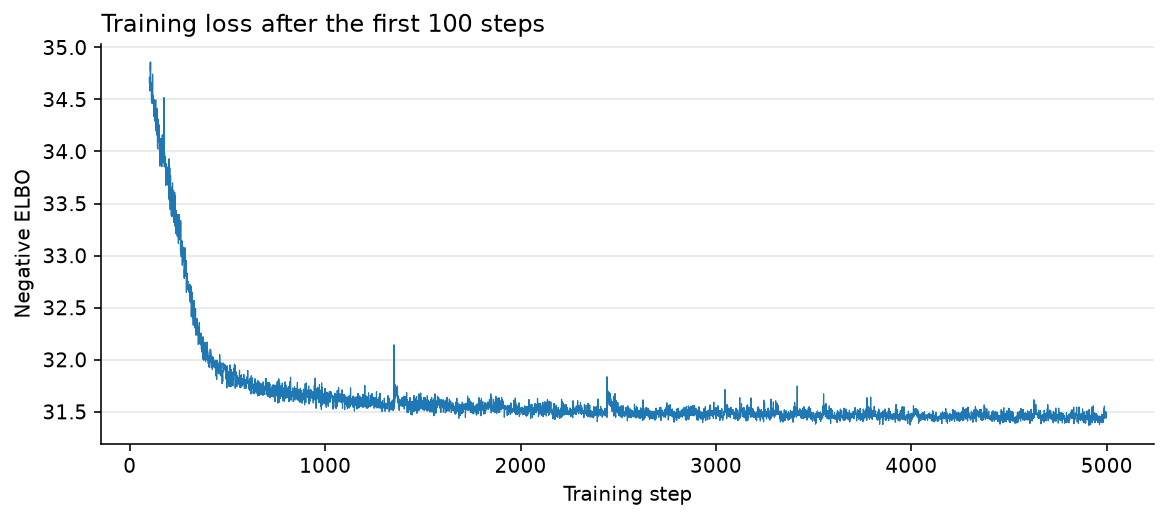

In [9]:
first_plotted_step = 100

fig, ax = plt.subplots(figsize=(8, 3.5), dpi=144, layout="constrained")
ax.plot(
    np.arange(first_plotted_step, n_steps),
    loss_history[first_plotted_step:],
    color="C0",
    linewidth=0.6,
)
ax.set(xlabel="Training step", ylabel="Negative ELBO")
ax.set_title(f"Training loss after the first {first_plotted_step} steps", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

The negative ELBO falls from 110 to below 32 within the first 500 steps and ends at 31.5.

## Comparing posteriors

Draws from the flow map back to the constrained space by exponentiating log tau. Two references follow. NUTS {cite:p}`hoffman2014nuts` on the non-centered parameterization, where each theta is mu plus tau times a standard normal offset, samples the funnel without trouble and serves as the ground truth. Mean-field ADVI {cite:p}`kucukelbir2017advi` on the centered model is the standard variational baseline, and it ends at a negative ELBO of 34.6.

In [10]:
n_draws = 4_000
sample_flow = pytensor.function([noise], samples)
flow_draws = sample_flow(noise_rng.standard_normal((n_draws, n_dims)))

unconstrained_draws = {
    value.name: flow_draws[:, start:stop]
    for value, start, stop in zip(value_vars, offsets[:-1], offsets[1:])
}
flow_posterior = {
    "mu": unconstrained_draws["mu"][:, 0],
    "tau": np.exp(unconstrained_draws["tau_log__"][:, 0]),
    "theta": unconstrained_draws["theta"],
}

In [11]:
with pm.Model(coords={"school": schools}) as noncentered_model:
    mu = pm.Normal("mu", mu=0.0, sigma=5.0)
    tau = pm.HalfCauchy("tau", beta=5.0)
    theta_offset = pm.Normal("theta_offset", mu=0.0, sigma=1.0, dims="school")
    theta = pm.Deterministic("theta", mu + tau * theta_offset, dims="school")
    pm.Normal("y", mu=theta, sigma=standard_error, observed=treatment_effect, dims="school")

    nuts = pm.sample(target_accept=0.95, random_seed=seed)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau, theta_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


In [12]:
with centered_model:
    mean_field = pm.fit(n=30_000, method="advi", random_seed=seed)
    advi = mean_field.sample(n_draws, random_seed=seed)

Output()

Finished [100%]: Average Loss = 34.614


In [13]:
def posterior_draws(idata):
    posterior = idata.posterior
    return {
        "mu": posterior["mu"].values.ravel(),
        "tau": posterior["tau"].values.ravel(),
        "theta": posterior["theta"].values.reshape(-1, len(schools)),
    }


def to_datatree(draws):
    posterior = {
        "mu": draws["mu"][None],
        "log_tau": np.log(draws["tau"])[None],
        "theta": draws["theta"][None],
    }
    return az.from_dict(
        {"posterior": posterior}, dims={"theta": ["school"]}, coords={"school": schools}
    )


approximations = {
    "NUTS, non-centered": posterior_draws(nuts),
    "Mean-field ADVI": posterior_draws(advi),
    "RealNVP flow": flow_posterior,
}
posteriors = {title: to_datatree(draws) for title, draws in approximations.items()}
comparison = xr.DataTree.from_dict(
    {
        "posterior": xr.concat(
            [posterior.posterior.to_dataset() for posterior in posteriors.values()],
            dim=pd.Index(list(posteriors), name="model"),
        )
    }
)

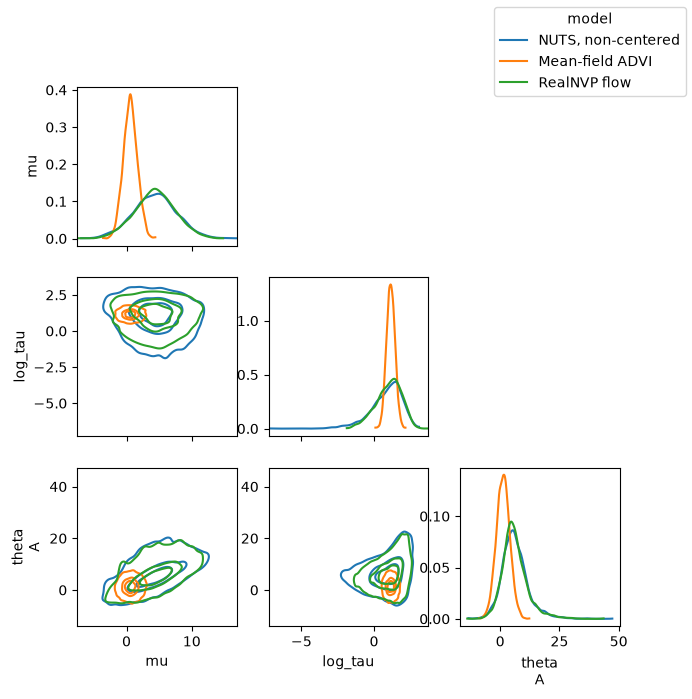

In [14]:
corner = az.plot_pair(
    comparison,
    var_names=["mu", "log_tau", "theta"],
    coords={"school": ["A"]},
    facet_dims=["__variable__", "school"],
    aes={"color": ["model"]},
    aes_by_visuals={"contour": ["color"], "dist": ["color"]},
    visuals={"scatter": False, "contour": True},
    figure_kwargs={"figsize": (7, 7)},
)
corner.add_legend("model")
plt.show()

The flow's contours match those from NUTS over the body of the posterior, including the way the spread of theta grows with tau. Mean-field ADVI treats every coordinate as independent and concentrates on a narrow region with mu near zero. The flow does miss the deepest part of the funnel's neck: 1% of its draws have log tau below -1.3, against -2.6 for NUTS. The ELBO is a reverse KL divergence, which penalizes placing mass where the posterior has little much more than it penalizes missing mass, so the fit gives up the thin neck.

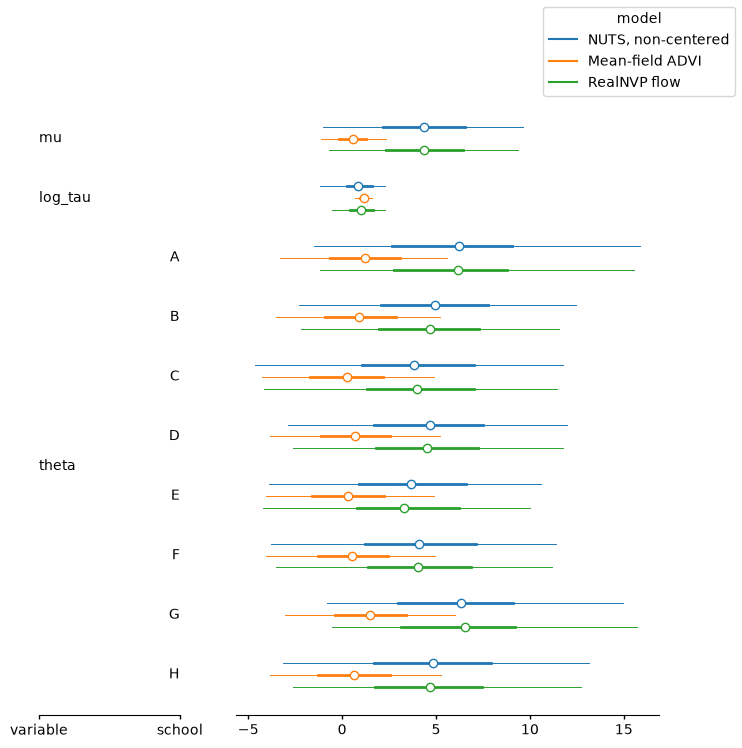

In [15]:
forest = az.plot_forest(
    posteriors,
    var_names=["mu", "log_tau", "theta"],
    combined=True,
    figure_kwargs={"figsize": (8, 8)},
)
forest.add_legend("model")
plt.show()

The forest plot shows the same pattern for every school. The flow's intervals line up with those from NUTS, while mean-field ADVI's are pulled toward zero and too narrow.

## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 8, 2026

## Watermark

In [16]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Sun, 08 Nov 2026

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.16.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

arviz      : 1.3.0
matplotlib : 3.11.2
numpy      : 2.5.4
pandas     : 3.0.5
pymc       : 6.4.0
pytensor   : 3.3.8
pytensor_ml: 0.4.0
tqdm       : 4.70.1
xarray     : 2026.9.0

Watermark: 2.6.0



# Thumbnail Image

The cell below draws this notebook's card image for the docs gallery: ten particles moving from the base noise through the affine layer and each coupling layer to the posterior, in the funnel plane of theta for school A against log tau. Its `gallery-thumbnail` tag selects it as the thumbnail, and its `remove-cell` tag, shared with this heading, keeps both off the rendered page.

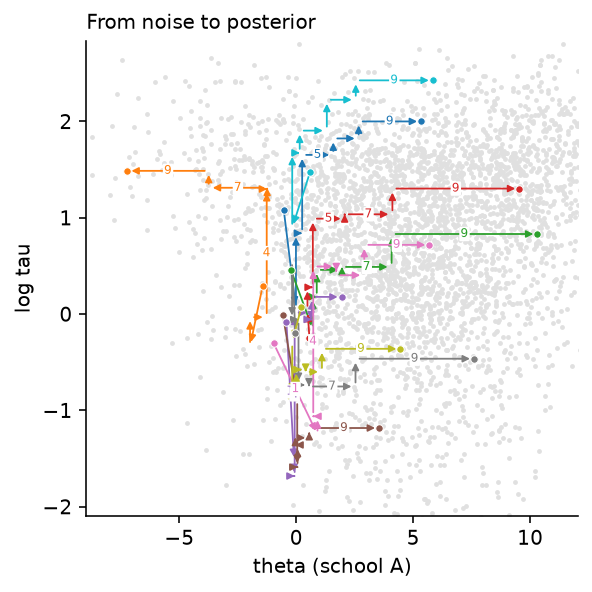

In [17]:
layer_outputs = [noise, affine(noise)]
for mask, network in zip(masks, coupling_networks):
    layer_outputs.append(couple(layer_outputs[-1], mask, network)[0])
trace_layers = pytensor.function([noise], layer_outputs)

n_particles = 10
theta_a_column = offsets[value_vars.index(centered_model.rvs_to_values[centered_model["theta"]])]
log_tau_column = offsets[value_vars.index(centered_model.rvs_to_values[centered_model["tau"]])]
particle_paths = np.stack(
    trace_layers(np.random.default_rng(seed).standard_normal((n_particles, n_dims)))
)
plane_paths = particle_paths[:, :, [theta_a_column, log_tau_column]]

lower, upper = plane_paths.reshape(-1, 2).min(axis=0), plane_paths.reshape(-1, 2).max(axis=0)
margin = 0.1 * (upper - lower)
lower, upper = lower - margin, upper + margin
# Label only moves long enough to hold a number without covering the arrow.
min_labeled_move = 0.06 * np.linalg.norm(upper - lower)

fig, ax = plt.subplots(figsize=(4, 4), dpi=144, layout="constrained")
ax.scatter(
    approximations["NUTS, non-centered"]["theta"][:, 0],
    np.log(approximations["NUTS, non-centered"]["tau"]),
    s=2,
    color="0.88",
    zorder=0,
)
for particle in range(n_particles):
    path = plane_paths[:, particle]
    color = f"C{particle}"
    ax.scatter(*path[[0, -1]].T, s=14, color=color, edgecolor="white", linewidth=0.5, zorder=3)
    for step, (start, end) in enumerate(pairwise(path), start=1):
        ax.annotate(
            "",
            xy=end,
            xytext=start,
            arrowprops={"arrowstyle": "-|>", "color": color, "linewidth": 0.9, "mutation_scale": 7},
            zorder=2,
        )
        if np.linalg.norm(end - start) > min_labeled_move:
            ax.text(
                *(start + end) / 2,
                str(step),
                color=color,
                fontsize=6,
                ha="center",
                va="center",
                bbox={"boxstyle": "round,pad=0.1", "facecolor": "white", "edgecolor": "none"},
                zorder=4,
            )

ax.set(
    xlabel="theta (school A)",
    ylabel="log tau",
    xlim=(lower[0], upper[0]),
    ylim=(lower[1], upper[1]),
)
ax.set_title("From noise to posterior", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.show()